<a href="https://colab.research.google.com/github/AbelCruzMartinezm12/DETECTOR-DE-SE-ALES/blob/main/Fase_1_y_2_detector_de_se%C3%B1ales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np


import matplotlib.pyplot as plt


import scipy.signal as signal


from sklearn.model_selection import train_test_split


import tensorflow as tf
from tensorflow.keras import layers, models

print("¡Librerías importadas correctamente!")

¡Librerías importadas correctamente!


In [ ]:
# 1.2 Definir los parámetros de la señal
fs = 1000  # Frecuencia de muestreo (Hz)
fc = 100   # Frecuencia de la portadora (Hz)
Rs = 10    # Tasa de símbolos (Baudios)

# Variables de apoyo para la generación de las ondas
muestras_por_simbolo = fs // Rs  # Número de puntos para dibujar un '1' o un '0'
t_simbolo = 1 / Rs               # Duración en tiempo de un solo símbolo

# Vector de tiempo (eje X para las gráficas)
t = np.arange(0, t_simbolo, 1/fs)

print(f"Frecuencia de muestreo (fs): {fs} Hz")
print(f"Frecuencia portadora (fc): {fc} Hz")
print(f"Tasa de símbolos (Rs): {Rs} Baudios")
print(f"Muestras generadas por cada símbolo: {muestras_por_simbolo}")

Frecuencia de muestreo (fs): 1000 Hz
Frecuencia portadora (fc): 100 Hz
Tasa de símbolos (Rs): 10 Baudios
Muestras generadas por cada símbolo: 100


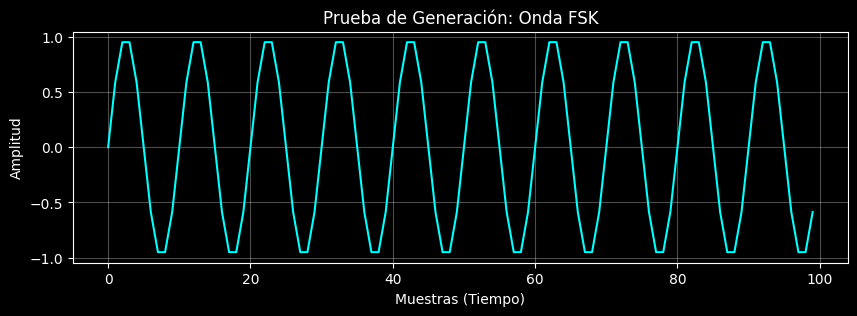

In [ ]:
# 1.3 Programar los generadores de señales
# Configuramos las gráficas con tema oscuro para una mejor visualización de las ondas
plt.style.use('dark_background')

def generar_muestra_ask(fs, fc, Rs):
    t = np.arange(0, 1/Rs, 1/fs)
    bit = np.random.randint(0, 2) # Genera un 0 o un 1 al azar
    # Teoría: El bit 1 tiene amplitud alta y el 0 amplitud cero
    amplitud = 1.0 if bit == 1 else 0.0
    onda = amplitud * np.sin(2 * np.pi * fc * t)
    return onda

def generar_muestra_fsk(fs, fc, Rs):
    t = np.arange(0, 1/Rs, 1/fs)
    bit = np.random.randint(0, 2)
    # Teoría: El 1 es una frecuencia y el 0 es otra[cite: 1]
    frecuencia = fc if bit == 1 else fc / 2
    onda = np.sin(2 * np.pi * frecuencia * t)
    return onda

def generar_muestra_psk(fs, fc, Rs):
    t = np.arange(0, 1/Rs, 1/fs)
    bit = np.random.randint(0, 2)
    # Teoría: En BPSK el 1 es fase 0° y el 0 es 180° (pi radianes)[cite: 1]
    fase = 0 if bit == 1 else np.pi
    onda = np.sin(2 * np.pi * fc * t + fase)
    return onda

def generar_muestra_qam16(fs, fc, Rs):
    t = np.arange(0, 1/Rs, 1/fs)
    # Teoría: Combina cambios de amplitud y fase[cite: 1]
    # En 16-QAM hay 16 combinaciones posibles. Lo representamos matemáticamente
    # usando componentes en fase (I) y cuadratura (Q).
    I = np.random.choice([-3, -1, 1, 3])
    Q = np.random.choice([-3, -1, 1, 3])
    onda = I * np.cos(2 * np.pi * fc * t) - Q * np.sin(2 * np.pi * fc * t)
    return onda

# --- Prueba rápida para visualizar ---
onda_prueba = generar_muestra_fsk(fs, fc, Rs)
plt.figure(figsize=(10, 3))
plt.plot(onda_prueba, color='cyan')
plt.title("Prueba de Generación: Onda FSK")
plt.xlabel("Muestras (Tiempo)")
plt.ylabel("Amplitud")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# 1.4 Generar el conjunto de datos
num_muestras_por_clase = 1000 # Mínimo 1,000 muestras por cada tipo

X_datos = []
y_etiquetas = []

print("Generando dataset, por favor espera un momento...")

for i in range(num_muestras_por_clase):
    # Generar y guardar ASK
    X_datos.append(generar_muestra_ask(fs, fc, Rs))
    y_etiquetas.append("ASK")

    # Generar y guardar FSK
    X_datos.append(generar_muestra_fsk(fs, fc, Rs))
    y_etiquetas.append("FSK")

    # Generar y guardar PSK
    X_datos.append(generar_muestra_psk(fs, fc, Rs))
    y_etiquetas.append("PSK")

    # Generar y guardar QAM (16-QAM)
    X_datos.append(generar_muestra_qam16(fs, fc, Rs))
    y_etiquetas.append("QAM")

# Convertir las listas estándar de Python a arreglos matriciales de NumPy
# (Esto es un requisito para que la Inteligencia Artificial pueda procesarlos en la Fase 2)
X = np.array(X_datos)
y = np.array(y_etiquetas)

print("¡Dataset generado con éxito!")
print(f"Total de señales (X): {X.shape[0]} muestras")
print(f"Longitud de cada señal: {X.shape[1]} puntos de datos")
print(f"Total de etiquetas (y): {y.shape[0]}")

Generando dataset, por favor espera un momento...
¡Dataset generado con éxito!
Total de señales (X): 4000 muestras
Longitud de cada señal: 100 puntos de datos
Total de etiquetas (y): 4000


Aplicando ruido a las señales para simular un canal real...


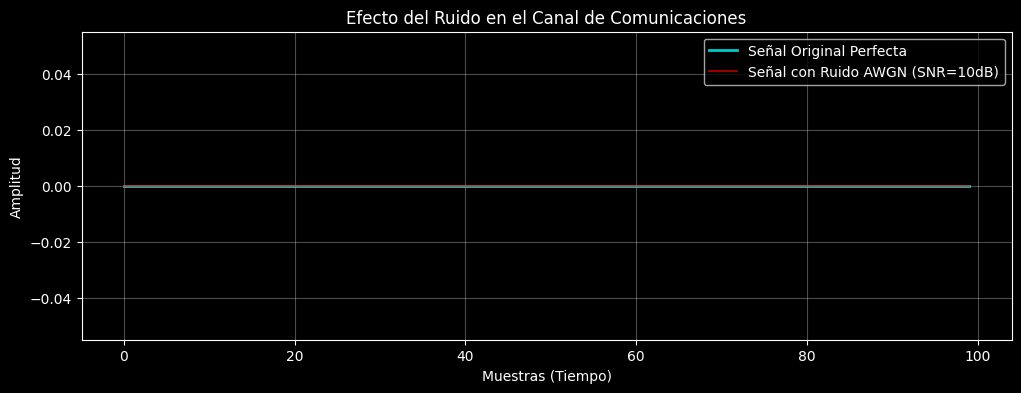

¡Ruido añadido exitosamente al dataset!


In [ ]:
# 1.5 Añadir Ruido Gaussiano Blanco Aditivo (AWGN)
def agregar_ruido_awgn(senal, snr_db):
    # 1. Calcular la potencia de la señal original
    potencia_senal = np.mean(senal**2)

    # 2. Convertir el valor de SNR de decibelios a escala lineal
    snr_lineal = 10**(snr_db / 10.0)

    # 3. Calcular la potencia del ruido requerida
    potencia_ruido = potencia_senal / snr_lineal

    # 4. Generar el ruido gaussiano y sumarlo a la señal
    ruido = np.random.normal(0, np.sqrt(potencia_ruido), len(senal))
    return senal + ruido

print("Aplicando ruido a las señales para simular un canal real...")

# Definimos un nivel de ruido medio (ej. 10 dB) para entrenar a la IA
snr_objetivo = 10

# Aplicamos la función a todas las señales de nuestro dataset (comprensión de listas)
X_ruidoso = np.array([agregar_ruido_awgn(senal, snr_objetivo) for senal in X])

# --- Visualizar la diferencia (Señal limpia vs Señal con ruido) ---
plt.figure(figsize=(12, 4))

# Graficamos la primera señal del dataset (ASK) limpia en cyan
plt.plot(X[0], color='cyan', label='Señal Original Perfecta', alpha=0.8, linewidth=2)

# Graficamos la misma señal pero con ruido en rojo por encima
plt.plot(X_ruidoso[0], color='red', label=f'Señal con Ruido AWGN (SNR={snr_objetivo}dB)', alpha=0.6)

plt.title("Efecto del Ruido en el Canal de Comunicaciones")
plt.xlabel("Muestras (Tiempo)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("¡Ruido añadido exitosamente al dataset!")

In [ ]:
# 1.6 Separación de datos y preparación de etiquetas
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

print("Preparando etiquetas y separando el conjunto de datos...")

# 1. Convertir las etiquetas de texto ("ASK", "FSK"...) a números (0, 1, 2, 3)
codificador = LabelEncoder()
y_numerico = codificador.fit_transform(y)

# 2. Convertir los números a formato binario "One-Hot"
# (Requisito estricto para 'categorical_crossentropy' en Keras)
y_one_hot = to_categorical(y_numerico)

# 3. Dividir los datos: 80% Entrenamiento y 20% Prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_ruidoso,
    y_one_hot,
    test_size=0.20,     # 20% para prueba, 80% para entrenamiento
    random_state=42,    # Semilla para que los resultados sean reproducibles
    stratify=y_one_hot  # Asegura la misma proporción de cada modulación en ambos grupos
)

# 4. Expandir las dimensiones de X para que la Red Convolucional (Conv1D) lo acepte
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("¡Fase 1 completada con éxito! 🎉")
print("-" * 40)
print(f"Dimensiones de Entrenamiento (80%): {X_train.shape} muestras listas")
print(f"Dimensiones de Prueba (20%): {X_test.shape} muestras listas")
print(f"Clases codificadas: {codificador.classes_}")

Preparando etiquetas y separando el conjunto de datos...
¡Fase 1 completada con éxito! 🎉
----------------------------------------
Dimensiones de Entrenamiento (80%): (3200, 100, 1) muestras listas
Dimensiones de Prueba (20%): (800, 100, 1) muestras listas
Clases codificadas: ['ASK' 'FSK' 'PSK' 'QAM']


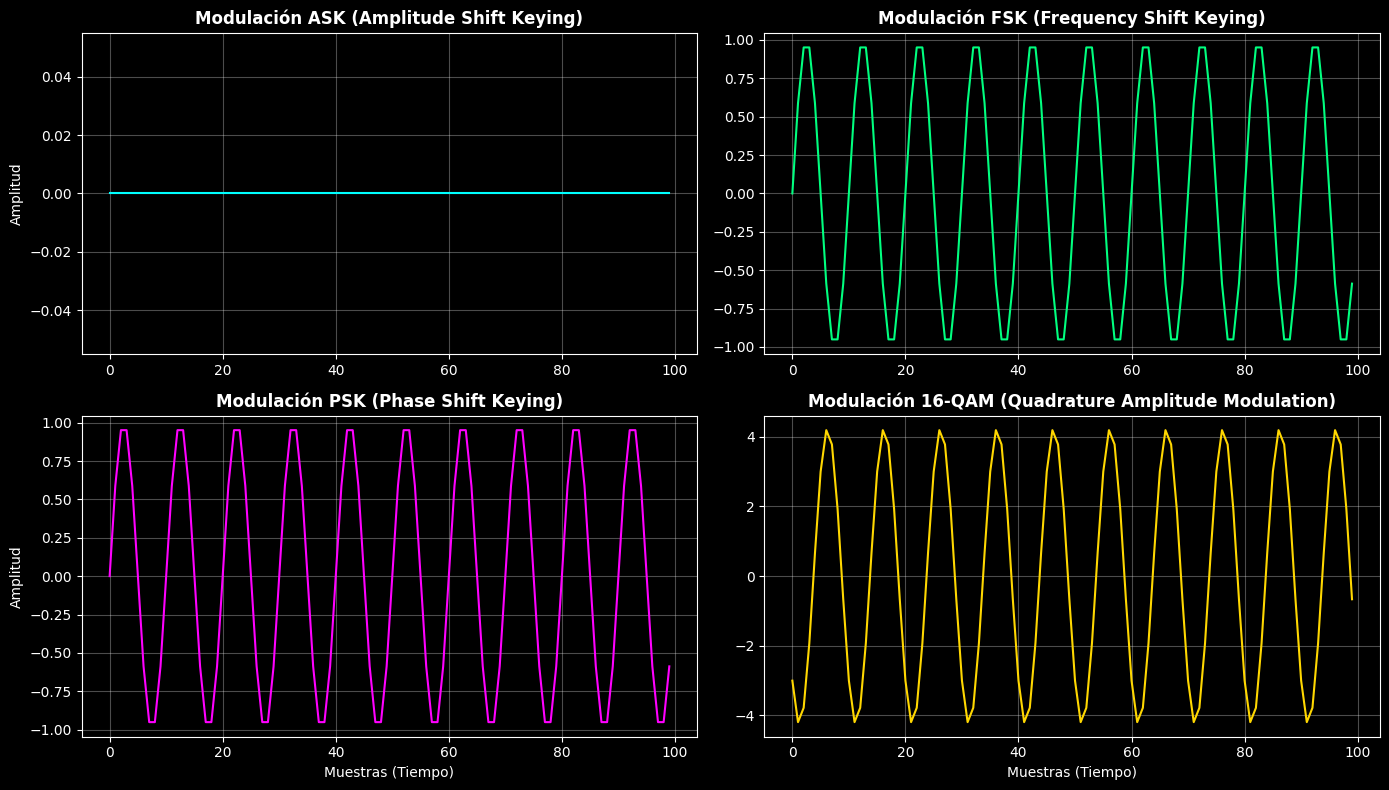

In [ ]:
# 1.3 Programar y visualizar los generadores de señales (4 modulaciones)
import matplotlib.pyplot as plt
import numpy as np

# Configuración de tema oscuro para resaltar las formas de onda
plt.style.use('dark_background')

def generar_muestra_ask(fs, fc, Rs):
    t = np.arange(0, 1/Rs, 1/fs)
    bit = np.random.randint(0, 2) # Genera un 0 o un 1 al azar
    amplitud = 1.0 if bit == 1 else 0.0
    onda = amplitud * np.sin(2 * np.pi * fc * t)
    return onda

def generar_muestra_fsk(fs, fc, Rs):
    t = np.arange(0, 1/Rs, 1/fs)
    bit = np.random.randint(0, 2)
    frecuencia = fc if bit == 1 else fc / 2
    onda = np.sin(2 * np.pi * frecuencia * t)
    return onda

def generar_muestra_psk(fs, fc, Rs):
    t = np.arange(0, 1/Rs, 1/fs)
    bit = np.random.randint(0, 2)
    fase = 0 if bit == 1 else np.pi
    onda = np.sin(2 * np.pi * fc * t + fase)
    return onda

def generar_muestra_qam16(fs, fc, Rs):
    t = np.arange(0, 1/Rs, 1/fs)
    I = np.random.choice([-3, -1, 1, 3])
    Q = np.random.choice([-3, -1, 1, 3])
    onda = I * np.cos(2 * np.pi * fc * t) - Q * np.sin(2 * np.pi * fc * t)
    return onda

# --- Generación de una muestra individual de cada clase ---
ask_sample = generar_muestra_ask(fs, fc, Rs)
fsk_sample = generar_muestra_fsk(fs, fc, Rs)
psk_sample = generar_muestra_psk(fs, fc, Rs)
qam_sample = generar_muestra_qam16(fs, fc, Rs)

# --- Visualización en matriz de 2x2 ---
fig, axs = plt.subplots(2, 2, figsize=(14, 8))

# ASK
axs[0, 0].plot(ask_sample, color='cyan', linewidth=1.5)
axs[0, 0].set_title("Modulación ASK (Amplitude Shift Keying)", color='white', fontweight='bold')
axs[0, 0].set_ylabel("Amplitud")
axs[0, 0].grid(True, alpha=0.3)

# FSK
axs[0, 1].plot(fsk_sample, color='springgreen', linewidth=1.5)
axs[0, 1].set_title("Modulación FSK (Frequency Shift Keying)", color='white', fontweight='bold')
axs[0, 1].grid(True, alpha=0.3)

# PSK
axs[1, 0].plot(psk_sample, color='magenta', linewidth=1.5)
axs[1, 0].set_title("Modulación PSK (Phase Shift Keying)", color='white', fontweight='bold')
axs[1, 0].set_xlabel("Muestras (Tiempo)")
axs[1, 0].set_ylabel("Amplitud")
axs[1, 0].grid(True, alpha=0.3)

# 16-QAM
axs[1, 1].plot(qam_sample, color='gold', linewidth=1.5)
axs[1, 1].set_title("Modulación 16-QAM (Quadrature Amplitude Modulation)", color='white', fontweight='bold')
axs[1, 1].set_xlabel("Muestras (Tiempo)")
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 2.2 Diseño del Modelo (Arquitectura 1D-CNN)
from tensorflow.keras import layers, models

# Obtenemos automáticamente la longitud de la señal (ej. 100 muestras)
longitud_senal = X_train.shape[1]

modelo = models.Sequential([
    # Capa de entrada y primera capa convolucional
    layers.Conv1D(filters=32, kernel_size=5, activation='relu', input_shape=(longitud_senal, 1)),
    layers.MaxPooling1D(pool_size=2),

    # Segunda capa convolucional para patrones más complejos (ej. 16-QAM)
    layers.Conv1D(filters=64, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2),

    # Aplanamiento de los mapas de características a un vector 1D
    layers.Flatten(),

    # Capa oculta densa para combinar características
    layers.Dense(64, activation='relu'),

    # Capa de salida: 4 neuronas (ASK, FSK, PSK, QAM) con activación Softmax
    layers.Dense(4, activation='softmax')
])

# 2.3 Compilar el modelo
modelo.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Mostrar el resumen de la arquitectura y parámetros entrenables
modelo.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_4 (Conv1D)               │ (None, 96, 32)         │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 48, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 46, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 23, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1472)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        94,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,932 (394.27 KB)

 Trainable params: 100,932 (394.27 KB)

 Non-trainable params: 0 (0.00 B)

Iniciando entrenamiento de la Red Neuronal...
Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.6625 - loss: 0.7308 - val_accuracy: 0.7700 - val_loss: 0.4408
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7459 - loss: 0.4502 - val_accuracy: 0.7575 - val_loss: 0.3964
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7450 - loss: 0.4357 - val_accuracy: 0.7588 - val_loss: 0.4086
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7472 - loss: 0.4361 - val_accuracy: 0.7650 - val_loss: 0.3967
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7547 - loss: 0.4305 - val_accuracy: 0.7750 - val_loss: 0.3935
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7681 - loss: 0.4265 - val_accuracy: 0.7613 - val_loss: 0.4182
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7628 - loss: 0.4215 - val_accuracy: 0.7575 - val_loss: 0.3875
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step 

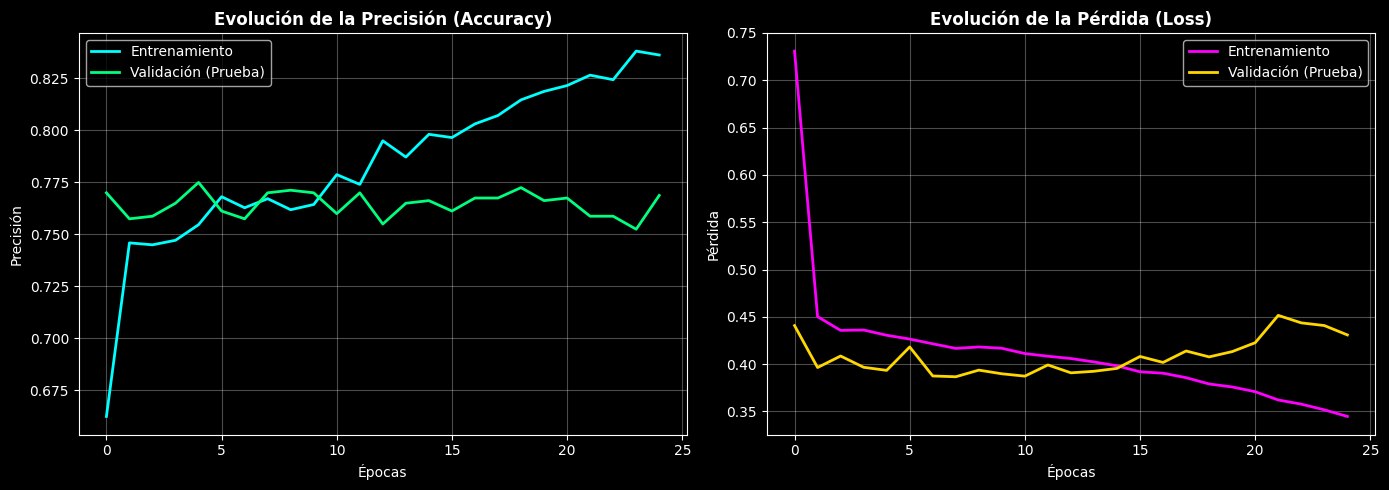

In [ ]:
# 2.4 Entrenar el modelo
print("Iniciando entrenamiento de la Red Neuronal...")

historial = modelo.fit(
    X_train, y_train,
    epochs=25,               # Número de pasadas completas por el dataset
    batch_size=32,           # Muestras procesadas antes de actualizar pesos
    validation_data=(X_test, y_test),
    verbose=1
)

# --- Graficar precisión y pérdida (Evidencia para el reporte) ---
plt.style.use('dark_background')
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Precisión (Accuracy)
axs[0].plot(historial.history['accuracy'], label='Entrenamiento', color='cyan', linewidth=2)
axs[0].plot(historial.history['val_accuracy'], label='Validación (Prueba)', color='springgreen', linewidth=2)
axs[0].set_title('Evolución de la Precisión (Accuracy)', fontweight='bold')
axs[0].set_xlabel('Épocas')
axs[0].set_ylabel('Precisión')
axs[0].legend()
axs[0].grid(True, alpha=0.3)

# Gráfica 2: Pérdida (Loss)
axs[1].plot(historial.history['loss'], label='Entrenamiento', color='magenta', linewidth=2)
axs[1].plot(historial.history['val_loss'], label='Validación (Prueba)', color='gold', linewidth=2)
axs[1].set_title('Evolución de la Pérdida (Loss)', fontweight='bold')
axs[1].set_xlabel('Épocas')
axs[1].set_ylabel('Pérdida')
axs[1].legend()
axs[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 2.5 Guardar el modelo entrenado
nombre_archivo = 'detective_senales_cnn.keras'
modelo.save(nombre_archivo)

print(f"¡Modelo guardado exitosamente como '{nombre_archivo}'!")

¡Modelo guardado exitosamente como 'detective_senales_cnn.keras'!
